## Generates Figures 5 and 6

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scattering_screen import ScatteringScreen
from scintstacker import ScintStacker
import concurrent.futures
import time
from functools import partial
from scipy.ndimage import gaussian_filter
import matplotlib.ticker as ticker
from scipy.optimize import curve_fit

In [15]:
compare_fast = np.load("data/alphaNHI_2d_compare_scint_noise_Tsys22.0_gain16.1_numcontours3_numstack500_fmin0.05_fmax5.0.npz")
alpha_arr = compare_fast["alpha_arr"]
NHI_arr = compare_fast["NHI_arr"]
deviation_scint = compare_fast["deviation_scint"]
deviation_noise = compare_fast["deviation_noise"]
deviation_fast = compare_fast["deviation"]

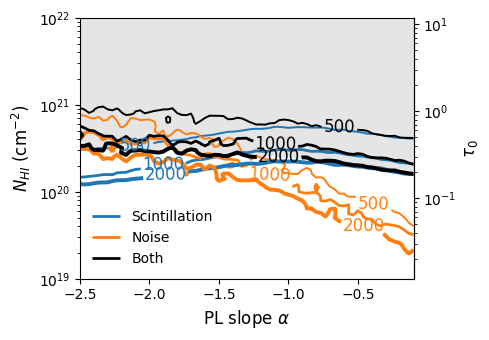

In [ ]:
fig, ax = plt.subplots(figsize=(5, 3.5))
X, Y = np.meshgrid(alpha_arr, NHI_arr)
handles = []
labels = []
for i in range(3):
    cont = ax.contour(X, Y, gaussian_filter(np.mean(deviation_scint[i], axis=0).T, 0.7), levels=[5], colors='C0', linewidths=np.sqrt(2**i*2))
    ax.clabel(cont, inline=True, fontsize=12, fmt={5: '{}'.format(2**(i)*500)})
    if i==1:
        handles.append(cont.legend_elements()[0][0])
        labels.append("Scintillation")
    cont = ax.contour(X, Y, gaussian_filter(np.mean(deviation_noise[i], axis=0).T, 0.7), levels=[5], colors='C1', linewidths=np.sqrt(2**i*2))
    ax.clabel(cont, inline=True, fontsize=12, fmt={5: '{}'.format(2**(i)*500)})
    if i==1:
        handles.append(cont.legend_elements()[0][0])
        labels.append("Noise")
    cont = ax.contour(X, Y, gaussian_filter(np.mean(deviation_fast[i], axis=0).T, 0.7), levels=[5], colors='k', linewidths=np.sqrt(2**i*2))
    ax.clabel(cont, inline=True, fontsize=12, fmt={5: '{}'.format(2**(i)*500)})
    if i==1:
        handles.append(cont.legend_elements()[0][0])
        labels.append("Both")
    elif i==2:
        ax.contourf(X, Y, gaussian_filter(np.mean(deviation_fast[i], axis=0).T, 0.7), levels=[5, 10000000000], colors='k', alpha=0.1)
ax.set_xscale('linear')
ax.set_yscale('log')
ax.set_xlabel(r'PL slope $\alpha$', fontsize=12)
ax.set_ylabel(r'$N_{HI}$ (cm$^{-2}$)', fontsize=12)
# ax.set_ylim(1e19, 1e22)
ax.legend(handles=handles, labels=labels, loc='lower left', fontsize=10, frameon=False)

secax = ax.secondary_yaxis('right', functions=(taumax, taumax_inv))
secax.set_ylabel(r'$\tau_0$', fontsize=12)

plt.tight_layout()
# plt.savefig("plots/alphaNHI_2d_scint_noise_compare_fast.png", dpi=300)

In [18]:
compare_gbt = np.load("data/alphaNHI_2d_compare_scint_noise_Tsys16.5_gain2.0_numcontours3_numstack250_fmin0.5_fmax70.0.npz")
alpha_arr = compare_gbt["alpha_arr"]
NHI_arr = compare_gbt["NHI_arr"]
deviation_scint = compare_gbt["deviation_scint"]
deviation_noise = compare_gbt["deviation_noise"]
deviation_gbt = compare_gbt["deviation"]

compare_gbt1 = np.load("data/alphaNHI_2d_compare_scint_noise_Tsys16.5_gain2.0_numcontours1_numstack100_fmin0.5_fmax70.0.npz")
deviation_scint1 = compare_gbt1["deviation_scint"]
deviation_noise1 = compare_gbt1["deviation_noise"]
deviation_gbt1 = compare_gbt1["deviation"]

deviation_scint = np.concatenate((deviation_scint1[:1], deviation_scint), axis=0)
deviation_noise = np.concatenate((deviation_noise1[:1], deviation_noise), axis=0)
deviation_gbt = np.concatenate((deviation_gbt1[:1], deviation_gbt), axis=0)

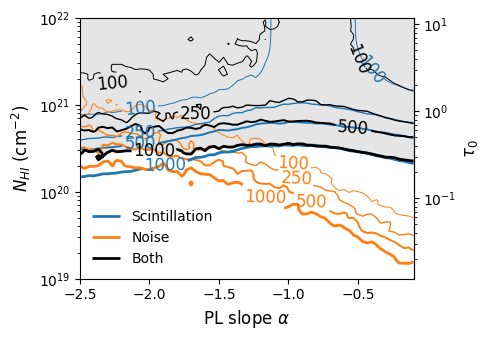

In [ ]:
fig, ax = plt.subplots(figsize=(5, 3.5))
X, Y = np.meshgrid(alpha_arr, NHI_arr)
handles = []
labels = []
clabel = [100, 250, 500, 1000]
for i in range(4):
    cont = ax.contour(X, Y, gaussian_filter(np.mean(deviation_scint[i], axis=0).T, 0.7), levels=[5], colors='C0', linewidths=np.sqrt(2**i/2))
    ax.clabel(cont, inline=True, fontsize=12, fmt={5: '{}'.format(clabel[i])})
    if i==3:
        handles.append(cont.legend_elements()[0][0])
        labels.append("Scintillation")
    cont = ax.contour(X, Y, gaussian_filter(np.mean(deviation_noise[i], axis=0).T, 0.7), levels=[5], colors='C1', linewidths=np.sqrt(2**i/2))#(i-0.5)*1.2)
    ax.clabel(cont, inline=True, fontsize=12, fmt={5: '{}'.format(clabel[i])})
    if i==3:
        handles.append(cont.legend_elements()[0][0])
        labels.append("Noise")
    cont = ax.contour(X, Y, gaussian_filter(np.mean(deviation_gbt[i], axis=0).T, 0.7), levels=[5], colors='k', linewidths=np.sqrt(2**i/2))#(i-0.5)*1.2)
    ax.clabel(cont, inline=True, fontsize=12, fmt={5: '{}'.format(clabel[i])})
    if i==3:
        handles.append(cont.legend_elements()[0][0])
        labels.append("Both")
        ax.contourf(X, Y, gaussian_filter(np.mean(deviation_gbt[i], axis=0).T, 0.7), levels=[5, 100000000000], colors='k', alpha=0.1)
ax.set_xscale('linear')
ax.set_yscale('log')
ax.set_xlabel(r'PL slope $\alpha$', fontsize=12)
ax.set_ylabel(r'$N_{HI}$ (cm$^{-2}$)', fontsize=12)
# ax.set_ylim(1e19, 1e22)
ax.legend(handles=handles, labels=labels, loc='lower left', fontsize=10, frameon=False)

secax = ax.secondary_yaxis('right', functions=(taumax, taumax_inv))
secax.set_ylabel(r'$\tau_0$', fontsize=12)

plt.tight_layout()
# plt.savefig("plots/alphaNHI_2d_scint_noise_compare_gbt.png", dpi=300)

In [2]:
scale = 1.2e10 #cm
dr = 1
lpi = dr
Rf = 86 # * lpi

nu_center = 0.57e8
dnu = 2e3
steps = 2000

scatscreen = ScatteringScreen(scale, lpi, Rf, nu_center, dnu, steps)

In [3]:
file = np.load("data/superscale_sc3000_86Rf_dnusc24.21kHz.npz")
amp_nu = file["amp_nu"]
del file
I_nu_temp = np.abs(amp_nu)**2
del amp_nu

print(I_nu_temp.shape)
Inu = []
delf = 2e4
nu = scatscreen.nu

(3000, 4001)


Median scintillation bandwidth: 26209.55 Hz
Mean scintillation bandwidth: 27885.60 Hz
Std scintillation bandwidth: 13053.97 Hz


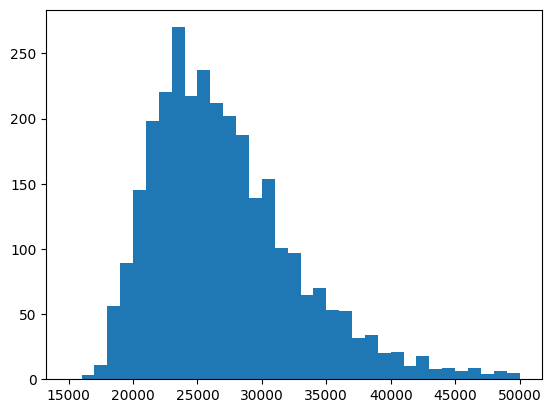

In [9]:
def fitacf(f, mi, fdc):
    return mi**2 / (1 + (f/fdc)**2) #+ height
    
def scint_bandwidth(I_nu, dnu):
    range_lag = 1500
    length = len(I_nu)
    I_avg = np.mean(I_nu)
    I_sub = I_nu - I_avg
    
    base = I_sub[:length - range_lag]
    
    # Vectorized autocorrelation
    corrlist = np.array([
        np.dot(base, I_sub[i : length - range_lag + i]) 
        for i in range(range_lag)
    ]) / ((length - range_lag) * (I_avg**2))

    deltanu = np.arange(range_lag) * dnu
    popt, _ = curve_fit(fitacf, deltanu, corrlist, p0=[0.9, 200])
    return popt[1]

sband = np.zeros(I_nu_temp.shape[0])
for i in range(sband.shape[0]):
    sband[i] = scint_bandwidth(I_nu_temp[i], dnu)

print(f"Median scintillation bandwidth: {np.median(sband):.2f} Hz")
print(f"Mean scintillation bandwidth: {np.mean(sband):.2f} Hz")
print(f"Std scintillation bandwidth: {np.std(sband):.2f} Hz")

bins = np.arange(15000, 50001, 1000)
plt.hist(sband, bins=bins)
plt.show()

In [11]:
def taumax(NHI, Ts=50, D=17.969):
    return 3.12e-5 * (NHI / 1e19) * (Ts / 1e4)**(-1) * ((0.96 * D**0.59)/10)**(-1)

def taumax_inv(tau, Ts=50, D=17.969):
    return tau / (3.12e-5 * (Ts / 1e4)**(-1) * ((0.96 * D**0.59)/10)**(-1)) * 1e19

def worker_wrapper(sobj, NHI_arr, num_stack, fmin, fmax, alpha, broken ,breaks):
    """
    Top-level wrapper for the worker function to be used with concurrent.futures.
    """
    return sobj.search1d_NHI(NHI_arr, num_stack=num_stack, fmin=fmin, fmax=fmax, alpha=alpha, broken=broken, breaks=breaks)

Tsys = 16.5
gain = 2.0
sobj_scint = ScintStacker(I_nu_temp[:,:-1], nu[:-1], nu_center, dnu, delf, scint_flag=True, noise_flag=False, fluxdist_flag=True, Tsys=Tsys, gain=gain)
sobj_noise = ScintStacker(I_nu_temp[:,:-1], nu[:-1], nu_center, dnu, delf, scint_flag=False, noise_flag=True, fluxdist_flag=True, Tsys=Tsys, gain=gain)
sobj = ScintStacker(I_nu_temp[:,:-1], nu[:-1], nu_center, dnu, delf, scint_flag=True, noise_flag=True, fluxdist_flag=True, Tsys=Tsys, gain=gain)

In [12]:
iter = 100
NHI_arr = np.logspace(19, 22, 61)
deviation1 = np.zeros((iter, len(NHI_arr)))
deviation1_scint = np.zeros((iter, len(NHI_arr)))
deviation2 = np.zeros((iter, len(NHI_arr)))
deviation2_scint = np.zeros((iter, len(NHI_arr)))

max_cores = 10

print(f"Starting parallel execution for {iter} iterations...")

bound_wrapper = partial(worker_wrapper, NHI_arr=NHI_arr, num_stack=100, fmin=0.5, fmax=70, alpha=[-0.7, -1.4], broken=1, breaks=7.8)

start_time = time.time()
with concurrent.futures.ProcessPoolExecutor(max_workers=max_cores) as executor:
    # We only need to pass the iterable of objects ([sobj] * iter) 
    # because the other parameters are frozen in 'bound_wrapper'
    results = executor.map(bound_wrapper, [sobj] * iter)

# Convert the iterator directly to a NumPy array
deviation1 = np.array(list(results))
end_time = time.time()
print(f"Parallel execution completed in {end_time - start_time:.2f} seconds.")

start_time = time.time()
with concurrent.futures.ProcessPoolExecutor(max_workers=max_cores) as executor:
    # We only need to pass the iterable of objects ([sobj] * iter) 
    # because the other parameters are frozen in 'bound_wrapper'
    results = executor.map(bound_wrapper, [sobj_scint] * iter)

# Convert the iterator directly to a NumPy array
deviation1_scint = np.array(list(results))
end_time = time.time()
print(f"Parallel execution completed in {end_time - start_time:.2f} seconds.")

bound_wrapper = partial(worker_wrapper, NHI_arr=NHI_arr, num_stack=500, fmin=0.5, fmax=70, alpha=[-0.7, -1.4], broken=1, breaks=7.8)

start_time = time.time()
with concurrent.futures.ProcessPoolExecutor(max_workers=max_cores) as executor:
    # We only need to pass the iterable of objects ([sobj] * iter) 
    # because the other parameters are frozen in 'bound_wrapper'
    results = executor.map(bound_wrapper, [sobj] * iter)

# Convert the iterator directly to a NumPy array
deviation2 = np.array(list(results))
end_time = time.time()
print(f"Parallel execution completed in {end_time - start_time:.2f} seconds.")

start_time = time.time()
with concurrent.futures.ProcessPoolExecutor(max_workers=max_cores) as executor:
    # We only need to pass the iterable of objects ([sobj] * iter) 
    # because the other parameters are frozen in 'bound_wrapper'
    results = executor.map(bound_wrapper, [sobj_scint] * iter)

# Convert the iterator directly to a NumPy array
deviation2_scint = np.array(list(results))
end_time = time.time()
print(f"Parallel execution completed in {end_time - start_time:.2f} seconds.")

Starting parallel execution for 100 iterations...


Parallel execution completed in 3.01 seconds.
Parallel execution completed in 3.45 seconds.
Parallel execution completed in 6.91 seconds.
Parallel execution completed in 3.02 seconds.


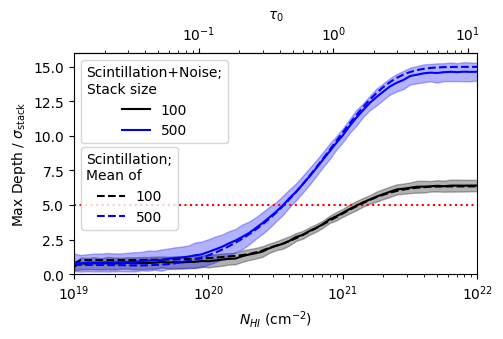

In [ ]:
mean_deviation1 = np.mean(deviation1, axis=0)
mean_deviation1_scint = np.mean(deviation1_scint, axis=0)
mean_deviation2 = np.mean(deviation2, axis=0)
mean_deviation2_scint = np.mean(deviation2_scint, axis=0)

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.axhline(5, color='r', ls=':')
ax.plot(NHI_arr, mean_deviation1, label="100", color='k')
ax.fill_between(NHI_arr, mean_deviation1 - np.std(deviation1, axis=0), mean_deviation1 + np.std(deviation1, axis=0), color='k', alpha=0.3)
ax.plot(NHI_arr, mean_deviation1_scint, label="100", color='k', ls='--')
ax.plot(NHI_arr, mean_deviation2, label="500", color='b')
ax.fill_between(NHI_arr, mean_deviation2 - np.std(deviation2, axis=0), mean_deviation2 + np.std(deviation2, axis=0), color='b', alpha=0.3)
ax.plot(NHI_arr, mean_deviation2_scint, label="500", color='b', ls='--')

ax.set_xscale("log")
ax.set_xlabel(r"$N_{HI}$ (cm$^{-2}$)")
ax.set_ylabel(r"Max Depth / $\sigma_{\rm stack}$")
ax.set_ylim(0, 16)
ax.set_xlim(1e19, 1e22)

secax = ax.secondary_xaxis('top', functions=(taumax, taumax_inv))
secax.set_xlabel(r"$\tau_{0}$")

handles, labels = ax.get_legend_handles_labels()
first_legend = ax.legend(handles=[handles[0], handles[2]], labels=[labels[0], labels[2]], title="Scintillation+Noise;\nStack size", loc="upper left")
ax.add_artist(first_legend)

ax.legend(handles=[handles[1], handles[3]], labels=[labels[1], labels[3]], title="Scintillation;\nMean of", loc=(0.017, 0.2))
plt.tight_layout()
# plt.savefig("plots/1d_NHI_frb20180916b_gbt.png", dpi=300)
plt.show()